<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# Test Environment for Generative AI classroom labs

This lab provides a test environment for the codes generated using the Generative AI classroom.

Follow the instructions below to set up this environment for further use.


# Setup


### Install required libraries

In case of a requirement of installing certain python libraries for use in your task, you may do so as shown below.


In [24]:
%pip install seaborn
import piplite

await piplite.install(['nbformat', 'plotly'])

### Dataset URL from the GenAI lab
Use the URL provided in the GenAI lab in the cell below. 


In [25]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-AI0271EN-SkillsNetwork/labs/v1/m3/data/used_car_price_analysis.csv"

### Downloading the dataset

Execute the following code to download the dataset in to the interface.

> Please note that this step is essential in JupyterLite. If you are using a downloaded version of this notebook and running it on JupyterLabs, then you can skip this step and directly use the URL in pandas.read_csv() function to read the dataset as a dataframe


In [26]:
from pyodide.http import pyfetch

async def download(url, filename):
    response = await pyfetch(url)
    if response.status == 200:
        with open(filename, "wb") as f:
            f.write(await response.bytes())

path = URL

await download(path, "dataset.csv")
file_name  = "dataset.csv"

---


# Test Environment


In [27]:
# Keep appending the code generated to this cell, or add more cells below this to execute in parts
import pandas as pd
data = pd.read_csv("dataset.csv")
statistics = data.describe(include="all")

print(statistics)

          model          year transmission        mileage fuelType  \
count     17966  17966.000000        17966   17966.000000    17966   
unique       24           NaN            3            NaN        5   
top      Fiesta           NaN       Manual            NaN   Petrol   
freq       6557           NaN        15518            NaN    12179   
mean        NaN   2016.866470          NaN   23362.608761      NaN   
std         NaN      2.050336          NaN   19472.054349      NaN   
min         NaN   1996.000000          NaN       1.000000      NaN   
25%         NaN   2016.000000          NaN    9987.000000      NaN   
50%         NaN   2017.000000          NaN   18242.500000      NaN   
75%         NaN   2018.000000          NaN   31060.000000      NaN   
max         NaN   2060.000000          NaN  177644.000000      NaN   

                 tax           mpg    engineSize         price  
count   17963.000000  17966.000000  17966.000000  17966.000000  
unique           NaN         

In [28]:
path = "path/to/your/file.csv"

dataframe = pd.read_csv("dataset.csv")
print(dataframe.head(5))

     model  year transmission  mileage fuelType    tax   mpg  engineSize  \
0   Fiesta  2017    Automatic    15944   Petrol  150.0  57.7         1.0   
1    Focus  2018       Manual     9083   Petrol  150.0  57.7         1.0   
2    Focus  2017       Manual    12456   Petrol  150.0  57.7         1.0   
3   Fiesta  2019       Manual    10460   Petrol  145.0  40.3         1.5   
4   Fiesta  2019    Automatic     1482   Petrol  145.0  48.7         1.0   

   price  
0  12000  
1  14000  
2  13000  
3  17500  
4  16500  


In [29]:
missing_columns = dataframe.columns[dataframe.isna().any()].tolist()
print("Columns with missing values:", missing_columns)

dataframe[missing_columns] = dataframe[missing_columns].fillna(
    dataframe[missing_columns].mean()
)

dataframe = dataframe.drop_duplicates()

# Load the dataset
df = pd.read_csv("dataset.csv")

# Check exact missing value counts per column
print(df.isnull().sum())

# Check data types and non-null entries
print(df.info())

Columns with missing values: ['tax']
model           0
year            0
transmission    0
mileage         0
fuelType        0
tax             3
mpg             0
engineSize      0
price           0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  object 
 1   year          17966 non-null  int64  
 2   transmission  17966 non-null  object 
 3   mileage       17966 non-null  int64  
 4   fuelType      17966 non-null  object 
 5   tax           17963 non-null  float64
 6   mpg           17966 non-null  float64
 7   engineSize    17966 non-null  float64
 8   price         17966 non-null  int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 1.0+ MB
None


In [30]:
target_column = "price"

correlations = (
    dataframe.select_dtypes(include="number")
    .corr()[target_column]
    .drop(target_column)
    .abs()
    .nlargest(5)
)

print(correlations)

year          0.635715
mileage       0.530483
engineSize    0.411451
tax           0.405970
mpg           0.346263
Name: price, dtype: float64


In [31]:
fuel_type_counts = dataframe["fuelType"].value_counts()

print(fuel_type_counts)

fuelType
Petrol      12081
Diesel       5706
Hybrid         22
Electric        2
Other           1
Name: count, dtype: int64


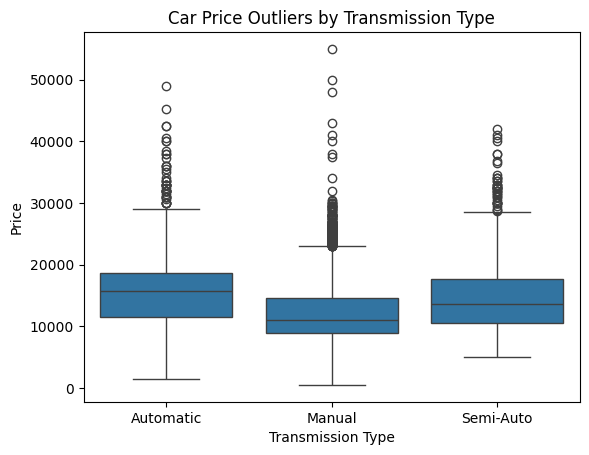

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=dataframe, x="transmission", y="price")
plt.title("Car Price Outliers by Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Price")
plt.show()

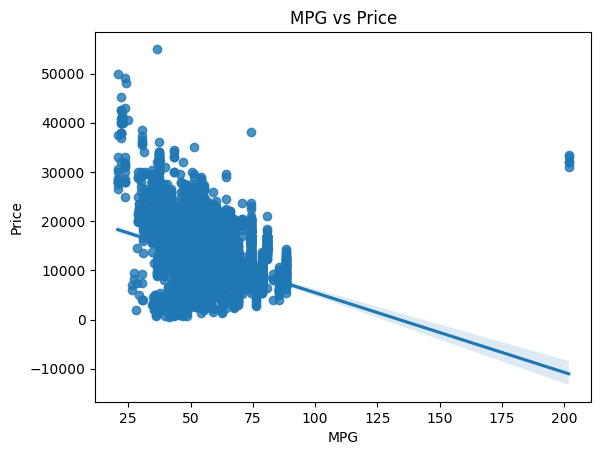

In [33]:
sns.regplot(data=dataframe, x="mpg", y="price")
plt.title("MPG vs Price")
plt.xlabel("MPG")
plt.ylabel("Price")
plt.show()

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

data = dataframe[["mpg", "price"]].dropna()

X = data[["mpg"]]
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)

R²: 0.1504343741072478
MSE: 19049855.140110757


In [35]:
features = ["year", "mileage", "tax", "mpg", "engineSize"]
data = dataframe[features + ["price"]].dropna()

X = data[features]
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)

R²: 0.6917125923771564
MSE: 6912744.910746688


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

features = ["year", "mileage", "tax", "mpg", "engineSize"]
data = dataframe[features + ["price"]].dropna()

X = data[features]
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2)),
    ("regression", LinearRegression())
])

pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)

R²: 0.12122807147174242
MSE: 19704749.61491952


In [38]:
from sklearn.linear_model import Ridge

features = ["year", "mileage", "tax", "mpg", "engineSize"]

data = dataframe[features + ["price"]].dropna()

X = data[features]
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train, y_train)

predictions = ridge_model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MSE:", mse)
print("R²:", r2)

MSE: 6912725.801054926
R²: 0.6917134446113138


In [39]:
features = ["year", "mileage", "tax", "mpg", "engineSize"]

data = dataframe[features + ["price"]].dropna()

X = data[features]
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

polynomial = PolynomialFeatures(degree=2)

X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train_scaled, y_train)

predictions = ridge_model.predict(X_test_scaled)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MSE:", mse)
print("R²:", r2)

MSE: 6919635.706767183
R²: 0.6914052838233121


In [40]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

features = ["year", "mileage", "tax", "mpg", "engineSize"]
data = dataframe[features + ["price"]].dropna()

X = data[features]
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ("polynomial", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

parameters = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    pipeline,
    parameters,
    cv=4,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train, y_train)

predictions = grid_search.predict(X_test)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Best alpha:", grid_search.best_params_["ridge__alpha"])
print("MSE:", mse)
print("R²:", r2)

Best alpha: 0.01
MSE: 8943741.429414164
R²: 0.6011363220655437


## Authors


[Abhishek Gagneja](https://www.linkedin.com/in/abhishek-gagneja-23051987/)


## Change Log


|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-12-10|0.1|Abhishek Gagneja|Initial Draft created|


Copyright © 2023 IBM Corporation. All rights reserved.
